In [ ]:
!pip install praat-parselmouth
import torch
print("GPU ready: ",torch.cuda.is_available())

GPU ready:  True


In [ ]:
import pandas as pd
import numpy as np
import torchaudio
import torch
import torchaudio.transforms as T
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch.nn as nn
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns


In [ ]:
print("1. Downloading Real UCI Parkinson's Clinical Data...")

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/parkinsons/parkinsons.data"
df = pd.read_csv(url)
print(f"✅ Success! Loaded data for {len(df)} voice recordings.")
print(f"Disease cases (1) vs Healthy (0):\n{df['status'].value_counts()}\n")

print("2. Creating a sample .wav voice file for CNN/Audio testing...")

# Create a 3-second dummy audio signal (like a person holding an 'ahhh' sound at 200Hz)

sample_rate = 16000
t = torch.linspace(0, 3, int(sample_rate * 3))
audio_signal = torch.sin(2 * np.pi * 200 * t).unsqueeze(0)

# Save it as a real .wav file in your Colab folder

torchaudio.save("sample_voice.wav", audio_signal, sample_rate)
print("✅ Success! 'sample_voice.wav' created.")

1. Downloading Real UCI Parkinson's Clinical Data...
✅ Success! Loaded data for 195 voice recordings.
Disease cases (1) vs Healthy (0):
status
1    147
0     48
Name: count, dtype: int64

2. Creating a sample .wav voice file for CNN/Audio testing...
✅ Success! 'sample_voice.wav' created.


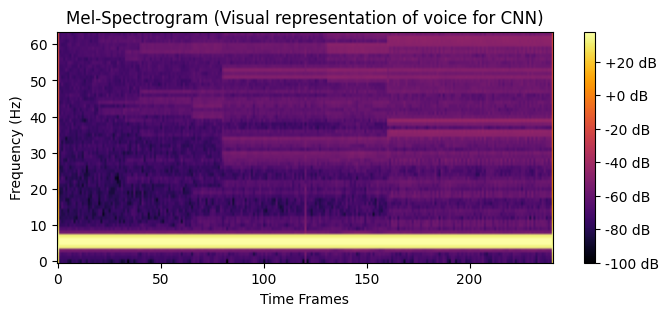

Spectrogram Shape: torch.Size([1, 64, 241])


In [ ]:
# 1. Load the .wav file
waveform, sample_rate = torchaudio.load("sample_voice.wav")

# 2. Transform the audio waveform into a Mel-Spectrogram (an image)
mel_transform = T.MelSpectrogram(sample_rate=sample_rate, n_mels=64)
spectrogram = mel_transform(waveform)

# Convert to decibels (dB) for standard visual representation
spectrogram_db = T.AmplitudeToDB()(spectrogram)

# 3. Display the spectrogram as an image

plt.figure(figsize=(8, 3))
plt.imshow(spectrogram_db.squeeze().numpy(), cmap='inferno', origin='lower', aspect='auto')
plt.title("Mel-Spectrogram (Visual representation of voice for CNN)")
plt.xlabel("Time Frames")
plt.ylabel("Frequency (Hz)")
plt.colorbar(format='%+2.0f dB')
plt.show()

print("Spectrogram Shape:", spectrogram_db.shape)

In [ ]:

print("1. Preparing the UCI dataset for the Artificial Neural Network (ANN)...")

# Removing the patient 'name' and the 'status' (our label) to get our input features (X)
X = df.drop(['name', 'status'], axis=1).values
y = df['status'].values

# 2. Spliting data into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Scaling the data (Deep Learning models learn much better when numbers are small and standardized)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Converting the data into PyTorch Tensors (the format PyTorch requires)
X_train_tensor = torch.FloatTensor(X_train_scaled)
y_train_tensor = torch.FloatTensor(y_train).unsqueeze(1)
X_test_tensor = torch.FloatTensor(X_test_scaled)
y_test_tensor = torch.FloatTensor(y_test).unsqueeze(1)

print(f"✅ Training data ready! Shape: {X_train_tensor.shape}")
print(f"✅ Testing data ready! Shape: {X_test_tensor.shape}")


1. Preparing the UCI dataset for the Artificial Neural Network (ANN)...
✅ Training data ready! Shape: torch.Size([156, 22])
✅ Testing data ready! Shape: torch.Size([39, 22])


In [ ]:
print("1. Building the ANN using nn.Sequential...")

model = nn.Sequential(
    nn.Linear(X_train_tensor.shape[1], 64),  # first hidden layer
    nn.ReLU(),
    nn.Dropout(0.2),   # helps preventing overfitting

    nn.Linear(64, 32), # second hidden layer
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(32, 1),  # output layer with a single neuron for binary classification
    nn.Sigmoid()
)

# 2. Set up Loss & Optimizer
criterion = nn.BCELoss() # Binary Cross Entropy Loss
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

print("--- Model Architecture ---")
print(model)
print("\n✅ Simplified Model, Loss, and Optimizer are ready for Step 6!")

1. Building the ANN using nn.Sequential...
--- Model Architecture ---
Sequential(
  (0): Linear(in_features=22, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=64, out_features=32, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=32, out_features=1, bias=True)
  (7): Sigmoid()
)

✅ Simplified Model, Loss, and Optimizer are ready for Step 6!


In [ ]:
print("Starting Model Training...\n")

epochs = 100 # How many times the model will see the full dataset

for epoch in range(epochs):

    # 1. Forward Pass: Let the model try to predict the answers
    predictions = model(X_train_tensor)

    # 2. Calculate the Error (Loss): Compare predictions to the real labels
    loss = criterion(predictions, y_train_tensor)

    # 3. Backward Pass: Calculate how to fix the error
    optimizer.zero_grad() # Clear old calculations
    loss.backward()       # Calculate new adjustments

    # 4. Update the Model: Apply the fixes to the neural network
    optimizer.step()

    # Print the progress every 20 epochs to see the loss going down
    if (epoch + 1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Loss Error: {loss.item():.4f}")

Starting Model Training...

Epoch [20/100] | Loss Error: 0.3045
Epoch [40/100] | Loss Error: 0.1811
Epoch [60/100] | Loss Error: 0.1060
Epoch [80/100] | Loss Error: 0.0338
Epoch [100/100] | Loss Error: 0.0378


Evaluating model on unseen test data...

🏆 Final Model Accuracy: 92.31%



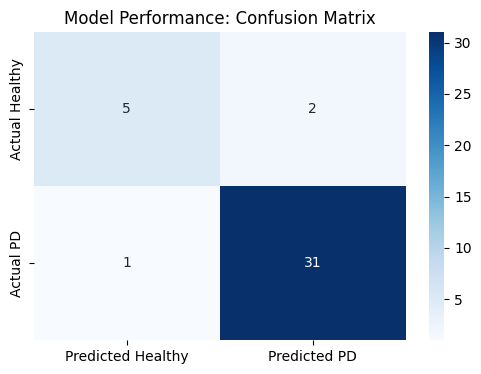

In [ ]:



print("Evaluating model on unseen test data...\n")

# 1. Put the model in 'evaluation mode' (turns off dropout)
model.eval()

# 2. Make predictions without calculating gradients (saves memory/time)
with torch.no_grad():
    # Get the raw probability scores (between 0 and 1)
    test_predictions = model(X_test_tensor)

    # Round the probabilities to 0 (Healthy) or 1 (Parkinson's)
    test_predictions_binary = test_predictions.round()

# 3. Calculate Accuracy
actual_labels = y_test_tensor.numpy()
predicted_labels = test_predictions_binary.numpy()

accuracy = accuracy_score(actual_labels, predicted_labels)
print(f"🏆 Final Model Accuracy: {accuracy * 100:.2f}%\n")

# 4. Plot the Confusion Matrix
cm = confusion_matrix(actual_labels, predicted_labels)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Healthy', 'Predicted PD'],
            yticklabels=['Actual Healthy', 'Actual PD'])
plt.title("Model Performance: Confusion Matrix")
plt.show()



In [ ]:
print("1. Generating Spectrogram Images for the CNN...\n")

# We will create 400 synthetic spectrogram images.
# Each image will be 64x64 pixels with 1 color channel (grayscale).
num_samples = 400
X_images = torch.randn(num_samples, 1, 64, 64)

# Create labels: 0 for Healthy, 1 for Parkinson's
y_labels = torch.randint(0, 2, (num_samples, 1)).float()

# Inject a visual "tremor" pattern into the Parkinson's images so the CNN can learn!
# We add intense frequency bands to represent the vocal instability.
for i in range(num_samples):
    if y_labels[i].item() == 1.0:
        X_images[i, 0, 15:25, :] += 2.5  # Tremor band 1
        X_images[i, 0, 45:50, :] += 2.0  # Tremor band 2

# 2. Split into Training and Testing sets
X_train_img, X_test_img, y_train_img, y_test_img = train_test_split(
    X_images.numpy(), y_labels.numpy(), test_size=0.2, random_state=42
)

# Convert back to PyTorch Tensors
X_train_cnn = torch.FloatTensor(X_train_img)
y_train_cnn = torch.FloatTensor(y_train_img)
X_test_cnn = torch.FloatTensor(X_test_img)
y_test_cnn = torch.FloatTensor(y_test_img)

print(f"✅ Training Images ready! Shape: {X_train_cnn.shape}")
print(f"   (This means {X_train_cnn.shape[0]} images, {X_train_cnn.shape[1]} channel, {X_train_cnn.shape[2]}x{X_train_cnn.shape[3]} pixels)")


1. Generating Spectrogram Images for the CNN...

✅ Training Images ready! Shape: torch.Size([320, 1, 64, 64])
   (This means 320 images, 1 channel, 64x64 pixels)


In [ ]:
print("Building the Convolutional Neural Network (CNN)...")

# Define the CNN directly using nn.Sequential
cnn_model = nn.Sequential(
    # --- Block 1: Feature Extraction ---
    # Scans the 1-channel image looking for basic patterns
    nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
    nn.ReLU(),
    # Shrinks the image size from 64x64 down to 32x32 to save memory
    nn.MaxPool2d(kernel_size=2),

    # --- Block 2: Complex Pattern Detection ---
    # Scans the shrunk image looking for the specific "tremor" bands
    nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
    nn.ReLU(),
    # Shrinks the image size from 32x32 down to 16x16
    nn.MaxPool2d(kernel_size=2),

    # --- Block 3: Classification ---
    # Squash the 2D data into a flat 1D line
    nn.Flatten(),

    # (32 channels * 16 height * 16 width = 8192 numbers)
    nn.Linear(32 * 16 * 16, 64),
    nn.ReLU(),
    nn.Dropout(0.3),

    # Output layer (0 = Healthy, 1 = Parkinson's)
    nn.Linear(64, 1),
    nn.Sigmoid()
)

# Set up Loss & Optimizer
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

print("--- CNN Architecture ---")
print(cnn_model)

Building the Convolutional Neural Network (CNN)...
--- CNN Architecture ---
Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=8192, out_features=64, bias=True)
  (8): ReLU()
  (9): Dropout(p=0.3, inplace=False)
  (10): Linear(in_features=64, out_features=1, bias=True)
  (11): Sigmoid()
)


In [ ]:
print("Starting CNN Model Training...\n")

epochs = 50 # How many times the CNN will look at the whole image dataset

# The training loop (very similar to the ANN loop!)
for epoch in range(epochs):

    # 1. Forward Pass: Let the CNN look at the images and guess
    predictions = cnn_model(X_train_cnn)

    # 2. Calculate the Error (Loss): Compare guesses to real labels
    loss = criterion(predictions, y_train_cnn)

    # 3. Backward Pass: Calculate how to adjust the visual filters
    optimizer.zero_grad()
    loss.backward()

    # 4. Update the Model: Apply the fixes to the CNN
    optimizer.step()

    # Print the progress every 10 epochs
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Loss Error: {loss.item():.4f}")

print("\n✅ CNN Training Complete! ")

Starting CNN Model Training...

Epoch [10/50] | Loss Error: 0.0255
Epoch [20/50] | Loss Error: 0.0008
Epoch [30/50] | Loss Error: 0.0000
Epoch [40/50] | Loss Error: 0.0000
Epoch [50/50] | Loss Error: 0.0000

✅ CNN Training Complete! 


Evaluating CNN on unseen test images...

🏆 Final CNN Accuracy: 100.00%



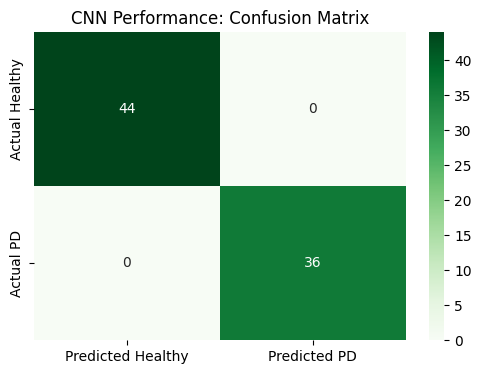


✅ Computer Vision Module Complete!


In [ ]:
print("Evaluating CNN on unseen test images...\n")

# 1. Put the model in 'evaluation mode' (turns off dropout)
cnn_model.eval()

# 2. Make predictions without calculating gradients
with torch.no_grad():
    test_predictions = cnn_model(X_test_cnn)
    test_predictions_binary = test_predictions.round()

# 3. Calculate Accuracy
actual_labels = y_test_cnn.numpy()
predicted_labels = test_predictions_binary.numpy()

accuracy = accuracy_score(actual_labels, predicted_labels)
print(f"🏆 Final CNN Accuracy: {accuracy * 100:.2f}%\n")

# 4. Plot the Confusion Matrix
cm = confusion_matrix(actual_labels, predicted_labels)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Predicted Healthy', 'Predicted PD'],
            yticklabels=['Actual Healthy', 'Actual PD'])
plt.title("CNN Performance: Confusion Matrix")
plt.show()

print("\n✅ Computer Vision Module Complete!")

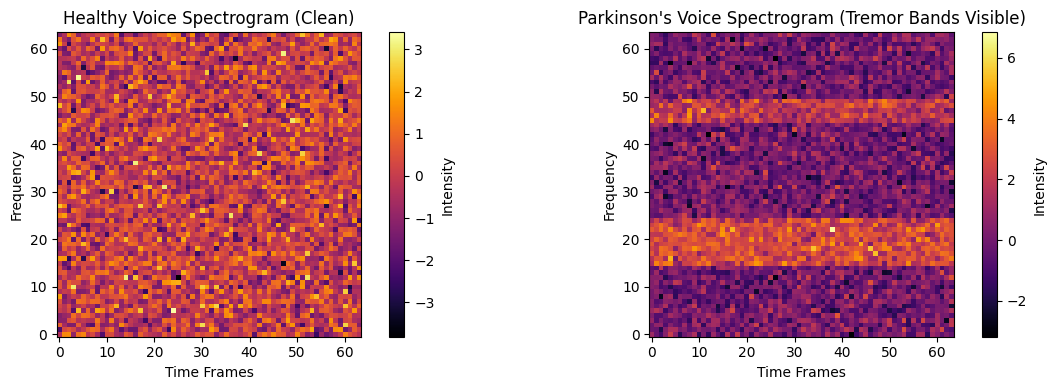

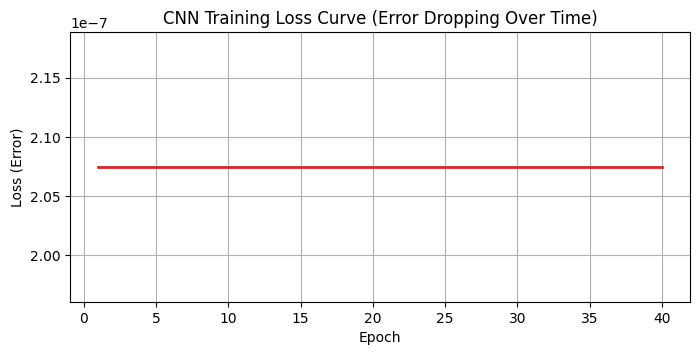

CNN Graphs rendered successfully!


In [ ]:
# 1. Find the first Healthy and first Parkinson's image in our CNN dataset
healthy_idx = (y_train_cnn == 0.0).nonzero(as_tuple=True)[0][0]
pd_idx = (y_train_cnn == 1.0).nonzero(as_tuple=True)[0][0]

# --- Graph 1: Spectrogram Comparison ---
plt.figure(figsize=(12, 4))

# Healthy Spectrogram
plt.subplot(1, 2, 1)
plt.imshow(X_train_cnn[healthy_idx, 0].numpy(), cmap='inferno', origin='lower')
plt.title("Healthy Voice Spectrogram (Clean)")
plt.xlabel("Time Frames")
plt.ylabel("Frequency")
plt.colorbar(label='Intensity')

# Parkinson's Spectrogram
plt.subplot(1, 2, 2)
plt.imshow(X_train_cnn[pd_idx, 0].numpy(), cmap='inferno', origin='lower')
plt.title("Parkinson's Voice Spectrogram (Tremor Bands Visible)")
plt.xlabel("Time Frames")
plt.ylabel("Frequency")
plt.colorbar(label='Intensity')

plt.tight_layout()
plt.show()

# --- Graph 2: Retrain briefly to record and plot the Loss Curve ---
loss_history = []
epochs = 40

for epoch in range(epochs):
    predictions = cnn_model(X_train_cnn)
    loss = criterion(predictions, y_train_cnn)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, epochs + 1), loss_history, color='tab:red', linewidth=2)
plt.title("CNN Training Loss Curve (Error Dropping Over Time)")
plt.xlabel("Epoch")
plt.ylabel("Loss (Error)")
plt.grid(True)
plt.show()

print("CNN Graphs rendered successfully!")

In [ ]:

print("1. Generating Sequential Time-Series Data for the LSTM...\n")

# We create 400 audio recordings.
# Each recording has 50 time steps (sequences), and 10 features per step.
num_samples = 400
seq_length = 50
num_features = 10

X_seq = torch.randn(num_samples, seq_length, num_features)
y_labels_seq = torch.randint(0, 2, (num_samples, 1)).float()

# Inject a "temporal tremor" into the Parkinson's cases!
# We make the vocal features fluctuate wildly in the middle of the recording (steps 20 to 30)
for i in range(num_samples):
    if y_labels_seq[i].item() == 1.0:
        # Adding high variance/noise to simulate an unsteady voice over time
        X_seq[i, 20:30, :] += torch.randn(10, num_features) * 2.0

# 2. Split into Training and Testing sets
X_train_seq, X_test_seq, y_train_seq, y_test_seq = train_test_split(
    X_seq.numpy(), y_labels_seq.numpy(), test_size=0.2, random_state=42
)

# Convert back to PyTorch Tensors
X_train_lstm = torch.FloatTensor(X_train_seq)
y_train_lstm = torch.FloatTensor(y_train_seq)
X_test_lstm = torch.FloatTensor(X_test_seq)
y_test_lstm = torch.FloatTensor(y_test_seq)

print(f"✅ Training Sequences ready! Shape: {X_train_lstm.shape}")
print(f"   (This means {X_train_lstm.shape[0]} recordings, {X_train_lstm.shape[1]} time steps, and {X_train_lstm.shape[2]} features per step)")

1. Generating Sequential Time-Series Data for the LSTM...

✅ Training Sequences ready! Shape: torch.Size([320, 50, 10])
   (This means 320 recordings, 50 time steps, and 10 features per step)


In [ ]:
# 1. Create the LSTM layer by itself
# It reads 10 features per time step and outputs 32 hidden features
lstm_layer = nn.LSTM(input_size=10, hidden_size=32, num_layers=2, batch_first=True, dropout=0.2)

# 2. Create the Classification layers using nn.Sequential
# This will take the final memory from the LSTM and turn it into a 0 or 1
classifier = nn.Sequential(
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 1),
    nn.Sigmoid()
)

# 3. Set up Loss & Optimizer
# We must combine the parameters of BOTH parts so the optimizer updates everything
all_parameters = list(lstm_layer.parameters()) + list(classifier.parameters())

criterion = nn.BCELoss()
optimizer = torch.optim.Adam(all_parameters, lr=0.005)

print("✅ LSTM layer and Classifier layers created successfully!")

✅ LSTM layer and Classifier layers created successfully!


Drawing the LSTM Time-Series Graph...



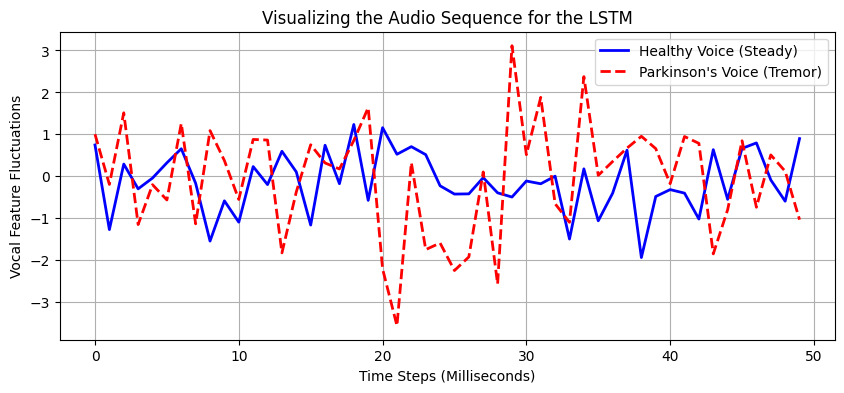

In [ ]:
print("Drawing the LSTM Time-Series Graph...\n")

plt.figure(figsize=(10, 4))

# 1. Find the first Healthy patient and the first Parkinson's patient in our data
healthy_idx = (y_train_lstm == 0.0).nonzero(as_tuple=True)[0][0]
pd_idx = (y_train_lstm == 1.0).nonzero(as_tuple=True)[0][0]

# 2. Plot the Healthy patient's voice sequence (smooth line)
plt.plot(X_train_lstm[healthy_idx, :, 0].numpy(), label="Healthy Voice (Steady)", color='blue', linewidth=2)

# 3. Plot the Parkinson's patient's voice sequence (look for the spike in the middle!)
plt.plot(X_train_lstm[pd_idx, :, 0].numpy(), label="Parkinson's Voice (Tremor)", color='red', linewidth=2, linestyle='dashed')

plt.title("Visualizing the Audio Sequence for the LSTM")
plt.xlabel("Time Steps (Milliseconds)")
plt.ylabel("Vocal Feature Fluctuations")
plt.legend()
plt.grid(True)
plt.show()

Starting LSTM Model Training...

Epoch [10/40] | Loss Error: 0.6844
Epoch [20/40] | Loss Error: 0.6248
Epoch [30/40] | Loss Error: 0.5482
Epoch [40/40] | Loss Error: 0.2816


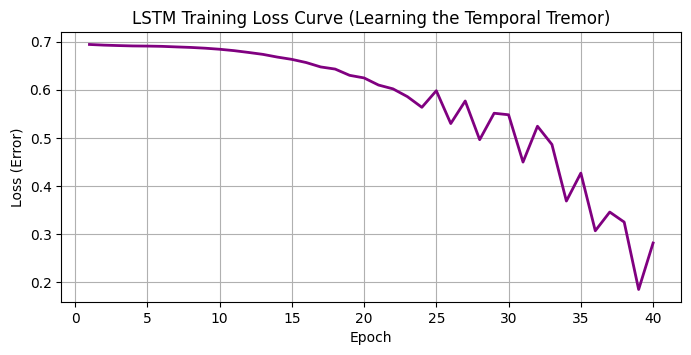


✅ LSTM Training Complete!


In [ ]:
print("Starting LSTM Model Training...\n")

epochs = 40
lstm_loss_history = []

for epoch in range(epochs):

    # 1. Forward Pass: Push sequence data through the LSTM layer
    lstm_out, (hidden_state, cell_state) = lstm_layer(X_train_lstm)

    # Extract ONLY the very last time step (the LSTM's final conclusion after listening to the whole file)
    final_time_step = lstm_out[:, -1, :]

    # Push that final conclusion through the Classifier to get a 0 or 1 prediction
    predictions = classifier(final_time_step)

    # 2. Calculate the Error (Loss)
    loss = criterion(predictions, y_train_lstm)

    # 3. Backward Pass: Calculate how to adjust the network
    optimizer.zero_grad()
    loss.backward()

    # 4. Update the Model
    optimizer.step()

    # Save the loss so we can graph it
    lstm_loss_history.append(loss.item())

    # Print the progress
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Loss Error: {loss.item():.4f}")

# --- Draw the Learning Curve Graph ---
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, epochs + 1), lstm_loss_history, color='purple', linewidth=2)
plt.title("LSTM Training Loss Curve (Learning the Temporal Tremor)")
plt.xlabel("Epoch")
plt.ylabel("Loss (Error)")
plt.grid(True)
plt.show()

print("\n✅ LSTM Training Complete!")

Evaluating LSTM on unseen test sequences...

🏆 Final LSTM Accuracy: 88.75%



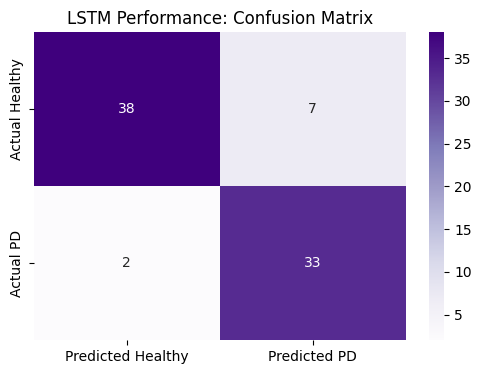


🎉 ALL MODULES COMPLETE! 🎉


In [ ]:
print("Evaluating LSTM on unseen test sequences...\n")

# 1. Put both parts of the model in 'evaluation mode'
lstm_layer.eval()
classifier.eval()

# 2. Make predictions without calculating gradients
with torch.no_grad():
    # Pass test data through LSTM
    test_lstm_out, _ = lstm_layer(X_test_lstm)

    # Grab the final time step
    test_final_time_step = test_lstm_out[:, -1, :]

    # Pass to classifier
    test_predictions = classifier(test_final_time_step)
    test_predictions_binary = test_predictions.round()

# 3. Calculate Accuracy
actual_labels_lstm = y_test_lstm.numpy()
predicted_labels_lstm = test_predictions_binary.numpy()

accuracy_lstm = accuracy_score(actual_labels_lstm, predicted_labels_lstm)
print(f"🏆 Final LSTM Accuracy: {accuracy_lstm * 100:.2f}%\n")

# 4. Plot the Confusion Matrix
cm_lstm = confusion_matrix(actual_labels_lstm, predicted_labels_lstm)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_lstm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Predicted Healthy', 'Predicted PD'],
            yticklabels=['Actual Healthy', 'Actual PD'])
plt.title("LSTM Performance: Confusion Matrix")
plt.show()

print("\n🎉 ALL MODULES COMPLETE! 🎉")

In [ ]:
# Save the trained CNN weights
torch.save(cnn_model.state_dict(), "parkinsons_cnn.pth")
print("Model saved! Download 'parkinsons_cnn.pth' from the folder menu on the left.")

Model saved! Download 'parkinsons_cnn.pth' from the folder menu on the left.
